In [1]:
import numpy as np
from openfermion import FermionOperator, QubitOperator, jordan_wigner

In [145]:
# H2 molecule
from pyscf import gto, scf

# Build molecule
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 0.74)]],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.11675930739643


np.float64(-1.1167593073964255)

In [146]:
from pyscf import fci

# singlets only
cisolver = fci.FCI(mol, mf.mo_coeff)
fci_energy, ci = cisolver.kernel()
print("FCI energy:", fci_energy)

FCI energy: -1.137283834488502


In [147]:
tol_ampl = 0.01

from pyscf.fci import cistring
mc = cisolver

ncas = mc.norb
nelec = mc.nelec

# determinants α i β (representats com enters amb bits d’ocupació)
na, nb = nelec
alpha_det = cistring.make_strings(range(ncas), na)
beta_det = cistring.make_strings(range(ncas), nb)


def interleave_bits(a, b, ncas):
    """Return interleaved occupation string (αβ αβ ...)"""
    a_bits = [(a >> i) & 1 for i in range(ncas)]
    b_bits = [(b >> i) & 1 for i in range(ncas)]
    inter = []
    for i in reversed(range(ncas)):
        inter.append(str(a_bits[i]))
        inter.append(str(b_bits[i]))
    return ''.join(inter)[::-1]

print('\namplitudes FCI')
for i, a in enumerate(alpha_det):
    for j, b in enumerate(beta_det):
        amp = mc.ci[i, j]
        if amp**2 > tol_ampl:
            # print(f"α={format(a, f'0{ncas}b')}  β={format(b, f'0{ncas}b')}  coef={amp:+.6f}")
            cfg = interleave_bits(a, b, ncas)
            print(f"{cfg}   {amp:+.6f}  ({amp**2:.6f}) ")


amplitudes FCI
1100   +0.993647  (0.987334) 
0011   -0.112544  (0.012666) 


In [148]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

e_nuc = mf.energy_nuc()

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)
print(e_nuc)

[[-1.25330979e+00  3.71049551e-17]
 [ 1.34841040e-17 -4.75068849e-01]]
[[[[ 6.74755927e-01 -3.75785642e-17]
   [-5.45047948e-17  1.81210462e-01]]

  [[-5.45047948e-17  1.81210462e-01]
   [ 6.63711401e-01  4.06319362e-16]]]


 [[[-3.75785642e-17  6.63711401e-01]
   [ 1.81210462e-01  5.57982113e-16]]

  [[ 1.81210462e-01  5.57982113e-16]
   [ 4.06319362e-16  6.97651504e-01]]]]
0.7151043390810812


In [149]:
from openfermion import InteractionOperator, jordan_wigner
from openfermion.chem.molecular_data import spinorb_from_spatial

h1_so, eri_so = spinorb_from_spatial(h1_mo, eri_mo)
hamiltonian = InteractionOperator(e_nuc, h1_so, 0.5 * eri_so)
ha_qubit = jordan_wigner(hamiltonian)

In [150]:
from openfermion import get_sparse_operator
H_sparse = get_sparse_operator(ha_qubit)
np.sort(np.linalg.eigvals(H_sparse.toarray()).real)

array([-1.13728383, -0.53820545, -0.53820545, -0.53077336, -0.53077336,
       -0.53077336, -0.44561582, -0.44561582, -0.16835243,  0.24003549,
        0.24003549,  0.3555207 ,  0.3555207 ,  0.48314267,  0.71510434,
        0.92317918])

In [167]:
# a b a b a b
# state = 0.993647 * FermionOperator('0^ 1^') -0.112544 * FermionOperator('2^ 3^')
state = FermionOperator('0^ 1^')

sparse_state = get_sparse_operator(state, n_qubits=4)


In [168]:
from scipy.sparse.linalg import expm, expm_multiply


def time_evolution_trotter(t):
    state_sparse = get_sparse_operator(state, n_qubits=4)
    for op in ha_qubit.get_operators():
        sparse_op = -1j*t * get_sparse_operator(op, n_qubits=4)
        state_sparse = expm_multiply(sparse_op, state_sparse)
    return state_sparse

def time_evolution(t):
    state_sparse = get_sparse_operator(state, n_qubits=4)
    sparse_op = -1j*t * get_sparse_operator(ha_qubit, n_qubits=4)
    state_sparse = expm_multiply(sparse_op, state_sparse)
    return state_sparse

Text(0.5, 0, 'time')

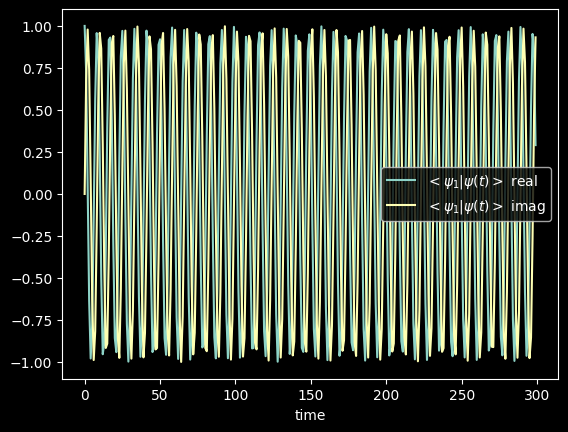

In [173]:
from openfermion import get_sparse_operator
import matplotlib.pyplot as plt


sparse_h = get_sparse_operator(ha_qubit, n_qubits=4)

overlap = []
times = []

import numpy as np
for t in np.linspace(0, 200, 300):
    sparse_state_t = time_evolution(t)
    overlap.append((sparse_state.T.conj() @ sparse_state_t)[0, 0])
    #print('energy: ', (sparse_state_t.T.conj() @ sparse_h @ sparse_state_t)[0, 0])

    times.append(t)

plt.plot(np.real(overlap), label='$<\psi_1 | \psi(t)>$ real')
plt.plot(np.imag(overlap), label='$<\psi_1 | \psi(t)>$ imag')

plt.legend()
plt.xlabel('time')
#plt.ylim(-1, 1)

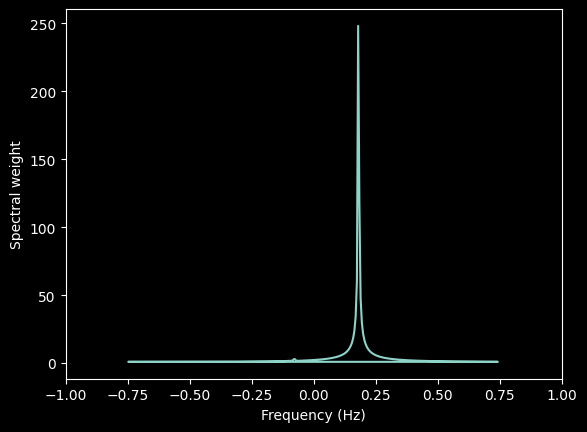

In [178]:
# Fourier transform
fft_signal = np.fft.fft(overlap)

# Frequencies
dt = times[1] - times[0]
N = fft_signal.size
freq = np.fft.fftfreq(N, dt)

plt.plot(freq, np.abs(fft_signal))

plt.xlim(-1, 1)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Spectral weight")
plt.show()

(-2.0, 0.0)

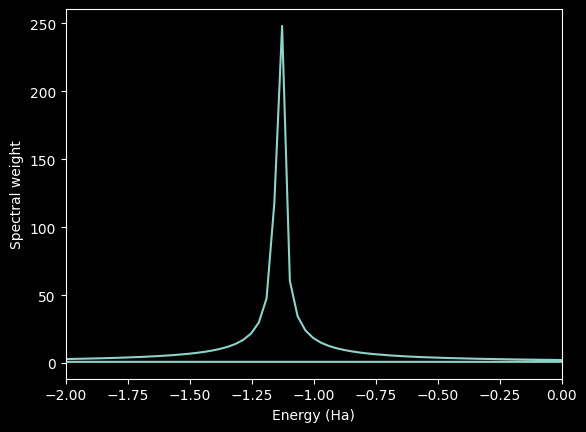

In [179]:
fft_signal = np.fft.fft(overlap)

freq = np.fft.fftfreq(len(times), times[1]-times[0])
energy = -2*np.pi*freq   # sign given by the convention e^{-iEt}

plt.plot(energy, np.abs(fft_signal))
plt.xlabel("Energy (Ha)")
plt.ylabel("Spectral weight")
plt.xlim(-2,0)